In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#databases = ["Reinstatement_information_2020.csv", "Reinstatement_information_2021.csv", "Reinstatement_information_2022 Jan-Nov.csv","Suspension_information_2020.csv", "Suspension_information_2021.csv", "Suspension_information_2022 Jan - Nov.csv", "Currently_Suspended_information.csv"]
databases = ["Reinstatement_information_2020.csv", 
             "Reinstatement_information_2021.csv", 
             "Reinstatement_information_2022 Jan-Nov.csv",
             "Currently_Suspended_information.csv"]

columns_to_read = ['Description', 'Term', 'Days Sus/Rev', 'Authority', 'Issuing Agency']

# Read the first CSV file
df_concat = pd.DataFrame()

# Iterate over the rest of the CSV files and merge them with the already merged DataFrame
for i in databases:
    df_next = pd.read_csv(i, usecols=columns_to_read)
    df_concat = pd.concat([df_concat, df_next], axis=0)

df_concat.head()
#df_concat.count()


,Description,Term,Days Sus/Rev,Authority,Issuing Agency
0,NON-PAYMENT OF CHILD SUPPORT,Indefinite,1072,NaN,NaN
1,PROPERTY DAMAGE CLAIM,Indefinite,714,NaN,NaN
2,NRVC Withdrawal,Indefinite,1191,NaN,NaN
3,NRVC Withdrawal,Indefinite,924,NaN,NaN
4,94C35 __ PRESENT WITH HEROIN,Definite,365,PD_GRA,Grafton Police Dept.


In [8]:
df_concat.info()

len(df_concat["Description"].unique())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 841299 entries, 0 to 693099
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   Description     841299 non-null  object
 1   Term            830360 non-null  object
 2   Days Sus/Rev    841299 non-null  object
 3   Authority       174096 non-null  object
 4   Issuing Agency  174096 non-null  object
dtypes: object(5)
memory usage: 38.5+ MB


197

In [47]:
description_count = df_concat.groupby("Description").size().sort_values(ascending=False)
total_count = description_count.sum()
description_percentages = round((description_count / total_count) * 100, 2)

description_count = description_count.reset_index()

result_df = pd.merge(description_count, description_percentages.rename('Percentage'), on='Description')

result_df.rename(columns={0: 'Number of Obeservations'}, inplace=True)

#Calculate the percentage of cases that can be explained by the top 10 reasons for license suspension 
print(result_df.head(10))
result = result_df.iloc[:10]
result["Percentage"].sum()

                       Description  Number of Obeservations  Percentage
0                  PAYMENT DEFAULT                   128703       15.30
1       Three Surchargeable Events                   104966       12.48
2           Major Disqualification                    89682       10.66
3                          WARRANT                    60607        7.20
4                    COURT DEFAULT                    51047        6.07
5        Ignition Interlock Device                    48076        5.71
6     NON-PAYMENT OF CHILD SUPPORT                    45647        5.43
7                COMPLAINT MEDICAL                    30876        3.67
8                  NRVC Withdrawal                    28499        3.39
9  Operating Under Influence (OUI)                    27087        3.22


73.13000000000001

<AxesSubplot:>

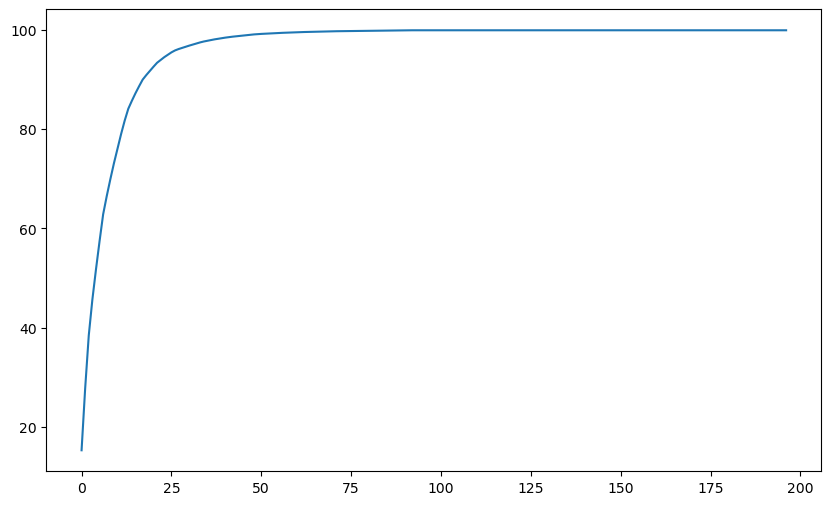

In [55]:
percentages = result_df["Percentage"]
cum_sum = np.cumsum(percentages)
cum_sum
cum_sum.plot(kind='line', figsize=(10, 6))

In [116]:
data = {'Description': result_df["Description"],
        'Percentages': cum_sum}
df = pd.DataFrame(data)
df.head(15)


,Description,Percentages
0,PAYMENT DEFAULT,15.30
1,Three Surchargeable Events,27.78
2,Major Disqualification,38.44
3,WARRANT,45.64
4,COURT DEFAULT,51.71
5,Ignition Interlock Device,57.42
6,NON-PAYMENT OF CHILD SUPPORT,62.85
7,COMPLAINT MEDICAL,66.52
8,NRVC Withdrawal,69.91
9,Operating Under Influence (OUI),73.13


## Q2: What % are not falling under safety related?

In [107]:
unique_values = df_concat['Term'].unique()
unique_values

array(['Indefinite', 'Definite', 'nan', 'Lifetime'], dtype=object)

In [115]:
df_concat["Term"] = df_concat["Term"].astype(str)
indefinites = df_concat[df_concat["Term"] == "Indefinite"].drop(columns = ["Authority", "Issuing Agency"])
indefinites= indefinites.dropna(subset=['Term'])
indefinites.head(20)
indefinites.groupby("Description").size().sort_values(ascending = False)
#indefinites.info()

Description
PAYMENT DEFAULT                              128702
Three Surchargeable Events                   104966
WARRANT                                       60607
COURT DEFAULT                                 51047
NON-PAYMENT OF CHILD SUPPORT                  45647
                                              ...  
U07 - Vehicular homicide                          1
LIQUOR, PERSON UNDER 21 POSSESS c138 §34C         1
INQREV __ CDL ILLEGAL STAT RSP                    1
LEARNERS PERMIT VIOLATION * c90 §8B               1
RHO __ RESUSP HTO                                 1
Length: 65, dtype: int64

In [9]:
definites = df_concat[df_concat["Term"] == "Definite"].drop(columns = ["Authority", "Issuing Agency"])
definites= definites.dropna(subset=['Term'])

definites.head(20)
#definites.info()
definites["Description"].unique()

array(['94C35 __ PRESENT WITH HEROIN', 'A33 - Illegal possess (drugs)',
       'Speeding', 'ADMIN PER SE', 'Operating Under Influence (OUI)',
       'Three Speeding Offenses', 'Seven Surchargeable Events',
       'LICENSE SUSPENDED, OP MV WITH c90 §23', 'Chemical Test Refusal',
       'D29 - Violate lic restrictions', 'Habitual Traffic Offender',
       'D36 - Failure to maintain liability insurance',
       'LICENSE SUSPENDED FOR OUI, OPER MV WITH c90 §23',
       'B24- DRIVING WHILE LIC DISQUAL',
       'LICENSE REVOKED AS HTO, OPERATE MV WITH * (CIVIL) c90 §23',
       'UNINSURED MOTOR VEHICLE c90 §34J',
       'B26 - Driving while suspended',
       'USE MV WITHOUT AUTHORITY c90 §24(2)(a)',
       'D02 - Misrepresent ID for lic', 'M81 - Careless/imprper driving',
       'Interlock Violation Offense',
       'LICENSE SUSPENDED, OP MV WITH, SUBSQ. OFF. c90 §23',
       'M84 - Reckless driving', 'NRVC Withdrawal',
       'Reciprocal Suspension', 'Youth Alcohol Program Suspension',
   

In [118]:
lifetime = df_concat[df_concat["Term"] == "Lifetime"].drop(columns = ["Authority", "Issuing Agency"])
lifetime = lifetime.dropna(subset=['Term'])
lifetime.info()
lifetime["Description"].unique()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 94504 entries, 13101 to 693095
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Description   94504 non-null  object
 1   Term          94504 non-null  object
 2   Days Sus/Rev  94504 non-null  object
dtypes: object(3)
memory usage: 2.9+ MB


array(['Chemical Test Refusal', 'Operating Under Influence (OUI)',
       'Interlock Violation Offense', 'Major Disqualification',
       'RUI __ RESUSP OUI',
       'MOTOR VEH HOMICIDE OUI--LIQUOR OR .08% c90 §24G(b)',
       'MOTOR VEH HOMICIDE BY NEGLIGENT OP c90 §24G(b)',
       'MOTOR VEH HOMICIDE OUI--LIQUOR OR .08% & NEGLIGENT c90 §24G(a)',
       'IMMEDIATE THREAT', 'A50 - Veh: controlled sbstance',
       'COURT ORDERED SUSPENSION',
       'MOTOR VEH HOMICIDE OUI--LIQUOR OR .08% & RECKLESS c90 §24G(a)',
       'ROH __ RESUSP OUI HOMICIDE', 'MANSLAUGHTER c265 §13',
       'MOTOR VEH HOMICIDE OUI--DRUGS & NEGLIG c90 §24G(a)',
       'MOTOR VEH HOMICIDE BY RECKLESS OP c90 §24G(b)',
       'MANSLAUGHTER WHILE OUI  c265 §13½', 'C80 __ CDL STV DISQUAL',
       'ADMIN PER SE', 'RVH __ RESUSP MV HOMICIDE',
       'B05 - Leave scne before police', 'COMPLAINT REGULATORY',
       'FAF __ FATAL ACCID FINAL', 'U08 - Vehicular manslaughter',
       'U09 - CMV negligent homicide', 'Massachus

,Description,Term,Days Sus/Rev,Authority,Issuing Agency
0,NON-PAYMENT OF CHILD SUPPORT,Indefinite,1072,NaN,NaN
1,PROPERTY DAMAGE CLAIM,Indefinite,714,NaN,NaN
2,NRVC Withdrawal,Indefinite,1191,NaN,NaN
3,NRVC Withdrawal,Indefinite,924,NaN,NaN
4,94C35 __ PRESENT WITH HEROIN,Definite,365,PD_GRA,Grafton Police Dept.
5,94C35 __ PRESENT WITH HEROIN,Definite,365,PD_WOR,Worcester Police Dept.
6,A33 - Illegal possess (drugs),Definite,365,PD_GRA,Grafton Police Dept.
7,A33 - Illegal possess (drugs),Definite,365,PD_SUT,Sutton Police Dept.
8,A33 - Illegal possess (drugs),Definite,365,PD_WOR,Worcester Police Dept.
9,IEW __ IID 2YR ERLY WTHDRL,Indefinite,4228,NaN,NaN
